# Lab 8 — Morphological Image Processing


---
## Theory — What is morphological processing?

**Morpholgical Processing** is modifying and improving the shapes in an image.

 The two ingredients of every morphological operation:

1. **The image** — a binary image where white (`255`) pixels are *foreground* (the object) and black (`0`) pixels are *background*.
2. **The structuring element** (also called *kernel* or *probe*) — a small shape (e.g., 3×3 square, 5×5 circle) that you slide across the image.

### The four basic operations
<img src="https://drive.google.com/thumbnail?id=129tujHkYNk3b8US7HEqbt-WymOZgwMnA&sz=w1000" width="600">



| Operation | What it does | Formula | Effect on objects |
|---|---|---|---|
| **Erosion** | Shrinks objects | $A \ominus B$ | Removes thin parts and noise |
| **Dilation** | Grows objects | $A \oplus B$ | Fills gaps, thickens objects |
| **Opening** | Erosion then dilation | $A \circ B = (A \ominus B) \oplus B$ | Removes small noise but keeps overall size |
| **Closing** | Dilation then erosion | $A \bullet B = (A \oplus B) \ominus B$ | Fills small holes but keeps overall size |

### How to remember each one

- **Erosion eats away** at object edges → output is smaller.
- **Dilation expands** object edges → output is larger.
- **Opening = "open up" the gaps** between separated noise specks (removes noise without shrinking real objects).
- **Closing = "close up" small holes** inside objects (fills gaps without growing real objects).



---
## Task 1 — Create a Binary Image with Shapes and Noise

The lab provides this code to generate a synthetic test image with **4 shapes** and some random **salt noise**:
- A solid filled circle on the left
- A solid filled rectangle
- A hollow (outline-only) circle
- A hollow rectangle
- Plus 1000 random scattered white pixels (noise)

## Setup — Import libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

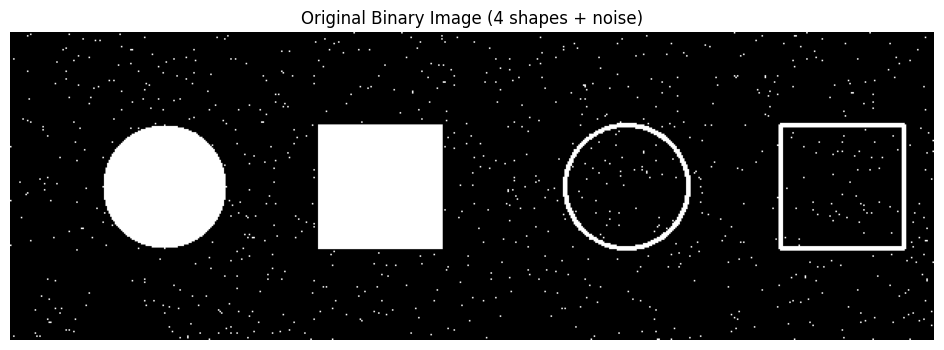

In [2]:
# Create a binary image with shapes and noise
image = np.zeros((200, 600), dtype=np.uint8)
cv2.circle(image, (100, 100), 40, 255, -1)              # Solid circle (filled) - radius=40
cv2.rectangle(image, (200, 60), (280, 140), 255, -1)    # Solid rectangle (filled) - start & end points= (200, 60), (280, 140)
cv2.circle(image, (400, 100), 40, 255, 2)               # Hollow circle (outline)
cv2.rectangle(image, (500, 60), (580, 140), 255, 2)     # Hollow rectangle (outline)

# Add small noise (1000 random white pixels)
np.random.seed(0)
for _ in range(1000):
    x, y = np.random.randint(0, 600), np.random.randint(0, 200)
    image[y, x] = 255

plt.figure(figsize=(12, 4))
plt.imshow(image, cmap='gray')
plt.title('Original Binary Image (4 shapes + noise)')
plt.axis('off')
plt.show()

---
Define the Structuring Element (5×5 Square Kernel)

The structuring element is the "shape" we slide across the image. The simplest one is a **square of all ones**:

$$K = \begin{bmatrix} 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \end{bmatrix}$$

**Why a square?** It's directionally neutral (same effect horizontally and vertically) and fast to compute. The `1`s indicate which positions in the neighborhood are "active" — for a square kernel, every neighbor counts.

In [3]:
kernel = np.ones((5, 5), np.uint8)
print("Square kernel (5×5):")
print(kernel)

Square kernel (5×5):
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


---
## Assessment Task 1 — Apply Erosion, Dilation, Opening, Closing (Square Kernel)

For each operation we use a single OpenCV function:

| Operation | OpenCV call |
|---|---|
| Erosion | `cv2.erode(image, kernel, iterations=1)` |
| Dilation | `cv2.dilate(image, kernel, iterations=1)` |
| Opening | `cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)` |
| Closing | `cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)` |



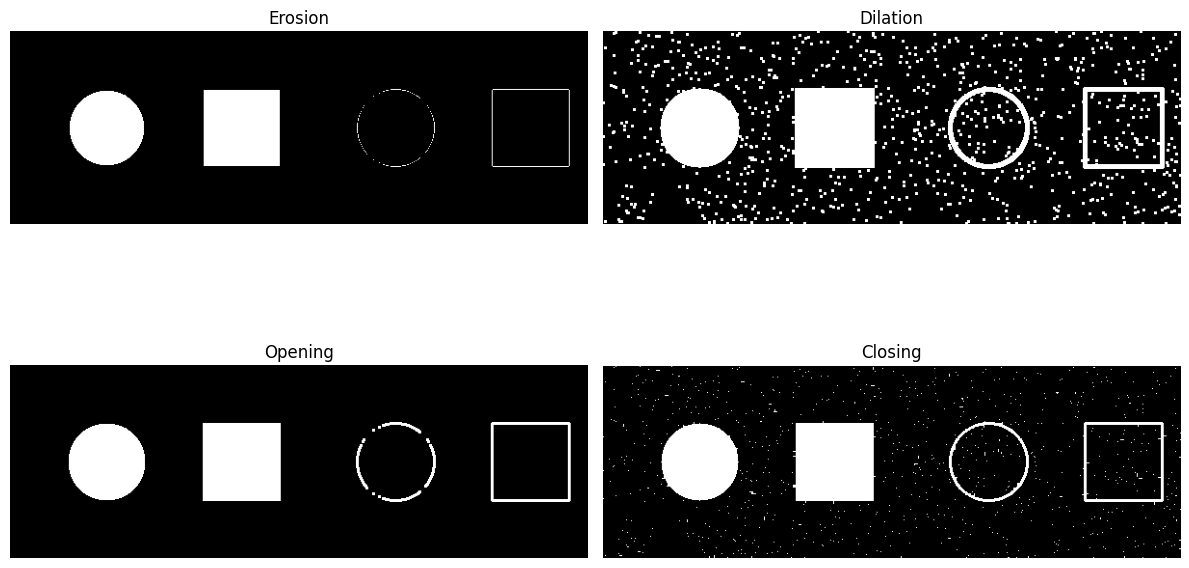

In [4]:
# Create a square kernel
kernel = np.ones((3, 3), dtype=np.uint8)

# Apply Erosion
erosion = cv2.erode(image, kernel, iterations=1)

# Apply Dilation
dilation = cv2.dilate(image, kernel, iterations=1)

# Apply Opening
opening = cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)

# Apply Closing
closing = cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

# Display results
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(erosion, cmap='gray')
plt.title('Erosion')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(dilation, cmap='gray')
plt.title('Dilation')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(opening, cmap='gray')
plt.title('Opening')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(closing, cmap='gray')
plt.title('Closing')
plt.axis('off')

plt.tight_layout()
plt.show()

## Assessment Task 2 — Repeat with a Circular Kernel

Apply erosion, dilation opening and closing to the generated image in Task#1 using the following structuring element:

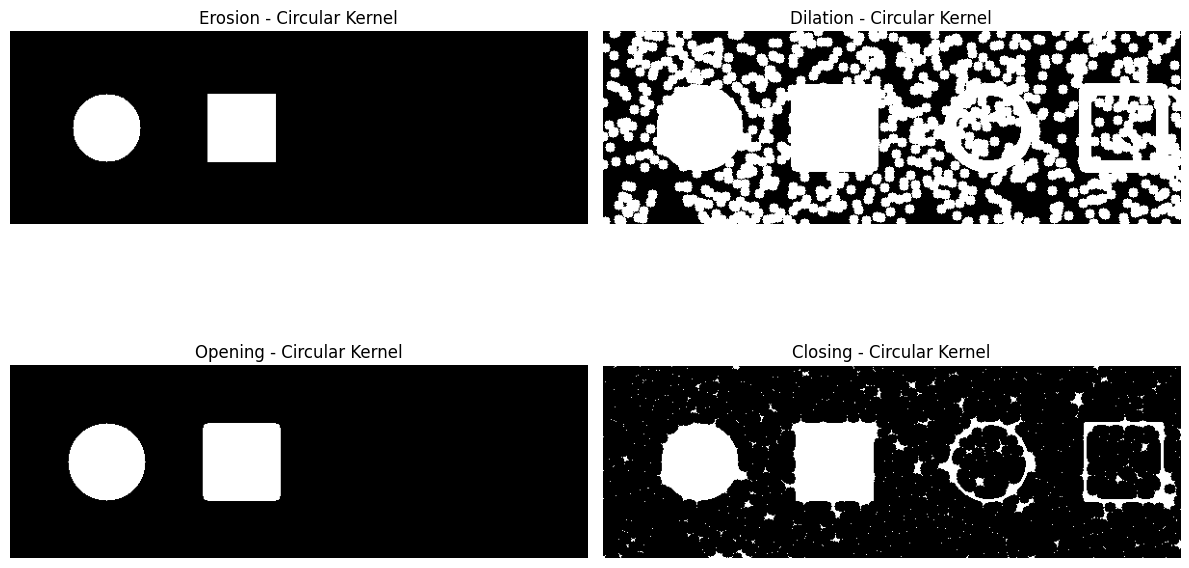

In [6]:
def circular_structuring_element(radius):
    """Creates a binary circular structuring element (exact circle)"""
    size = 2 * radius + 1
    kernel = np.zeros((size, size), dtype=np.uint8)
    cv2.circle(kernel, (radius, radius), radius, 1, -1)
    return kernel

# Define radius
radius = 5
circle_kernel = circular_structuring_element(radius)

# Apply Erosion
erosion_circle = cv2.erode(image, circle_kernel, iterations=1)

# Apply Dilation
dilation_circle = cv2.dilate(image, circle_kernel, iterations=1)

# Apply Opening
opening_circle = cv2.morphologyEx(
    image, cv2.MORPH_OPEN, circle_kernel
)

# Apply Closing
closing_circle = cv2.morphologyEx(
    image, cv2.MORPH_CLOSE, circle_kernel
)

# Display results
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(erosion_circle, cmap='gray')
plt.title('Erosion - Circular Kernel')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(dilation_circle, cmap='gray')
plt.title('Dilation - Circular Kernel')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(opening_circle, cmap='gray')
plt.title('Opening - Circular Kernel')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(closing_circle, cmap='gray')
plt.title('Closing - Circular Kernel')
plt.axis('off')

plt.tight_layout()
plt.show()

## Assessment Task 3 — Difference Between Square vs Circular Kernel

 In your own words, explain the difference between the results in Task#1 and Task#2



The square kernel affects the square shaped pixels while the circular kernel affects the circular shaped pixels. The square kernel may generate more square edges and the circular kernel generates smoother and more rounded edges. So the results of erosion, dilation, opening, and closing may vary with the kernel shape.